In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
import config
from src.utils import set_seed
set_seed(config.SEED)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": "#F5F1E8", "figure.facecolor": "#F5F1E8", "axes.edgecolor": "#77766D",
                     "font.size": 10, "axes.titleweight": "bold"})
PALETTE = ["#344C3D", "#BD755A", "#C4A46A", "#899982", "#77766D", "#242723"]
sns.set_palette(PALETTE)
def note(txt):  # data-driven observation rendered as markdown
    display(Markdown("> **Observation.** " + txt))

# 10 — Final Model Benchmarking and Deployment Choice

One consolidated, like-for-like comparison of **classical ML, deep learning and transformers** for sentence-role classification, followed by a *rule-based, evidence-driven* choice of the deployed model.

**Comparison design (read before the tables).**

1. **Common yardstick:** every model is scored on the *same* 2,000-sentence stratified test subset (`artifacts/evaluation/preds_*.npz`). Uncertainty is quantified by a **bootstrap (1,000 resamples) 95% CI** of macro-F1.
2. **Training budgets differ and are shown explicitly** (`train n`): classical NB/LR/SVM saw all 180,040 training sentences, RF/XGBoost/BiLSTM 30,000, the transformers 3,000. A **matched-budget** row (Logistic Regression trained on the same 3,000 sentences as the transformers) separates *architecture* from *data volume*.
3. Latency is wall-clock per sentence on this CPU **while other jobs were running** (notebooks were executed concurrently to fit one session), so absolute latencies are noisy; use them for *relative* ordering.

In [2]:
import itertools
from scipy.stats import chi2
from src.utils import load_json, save_json
from src.evaluation import classification_metrics
M = load_json(config.ART_CLS / "metrics.json"); LAB = config.CLASS_LABELS
import glob
preds = {p.split("preds_")[1][:-4]: np.load(p) for p in glob.glob(str(config.ART_EVAL / "preds_*.npz"))}
keys = [k for k in M if k in preds]
y = preds[keys[0]]["y"]; rng = np.random.default_rng(config.SEED)
def macro_f1(y_true, y_pred):
    f = []
    for c in range(5):
        tp = ((y_true == c) & (y_pred == c)).sum(); fp = ((y_true != c) & (y_pred == c)).sum(); fn = ((y_true == c) & (y_pred != c)).sum()
        f.append(2 * tp / (2 * tp + fp + fn) if tp else 0.0)
    return np.mean(f)
idx = rng.integers(0, len(y), (1000, len(y))); ci = {}
for k in keys:
    p = preds[k]["probs"].argmax(1); b = np.array([macro_f1(y[i], p[i]) for i in idx]); ci[k] = (np.percentile(b, 2.5), np.percentile(b, 97.5))
rows = {}
for k in keys:
    v = M[k]; tf = v.get("test_full")
    rows[k] = {"model": v["label"], "family": {"classical": "classical", "deep": "deep learning", "transformer": "transformer"}[v["kind"]], "train n": v["train_n"], "accuracy": v["accuracy"], "macro-F1": v["f1_macro"], "95% CI": f"{ci[k][0]:.3f}–{ci[k][1]:.3f}", "weighted-F1": v["f1_weighted"],
               "macro-P": v["precision_macro"], "macro-R": v["recall_macro"], "macro-F1 full test": (tf or {}).get("f1_macro", np.nan), "dev macro-F1": (v.get("dev") or {}).get("f1_macro", np.nan),
               "train s": v["train_seconds"], "ms/sent": v["latency_ms"], "MB": v["model_mb"], "params (M)": v.get("params", np.nan) / 1e6 if v.get("params") else np.nan}
bench = pd.DataFrame(rows).T.set_index("model").sort_values("macro-F1", ascending=False)
bench.style.format({c: "{:.4f}" for c in ["accuracy", "macro-F1", "weighted-F1", "macro-P", "macro-R", "macro-F1 full test", "dev macro-F1"]} | {"train s": "{:.0f}", "ms/sent": "{:.2f}", "MB": "{:.1f}", "params (M)": "{:.1f}"}, na_rep="n/a").background_gradient(subset=["macro-F1"], cmap="YlGn")

,family,train n,accuracy,macro-F1,95% CI,weighted-F1,macro-P,macro-R,macro-F1 full test,dev macro-F1,train s,ms/sent,MB,params (M)
model,,,,,,,,,,,,,,
BioBERT v1.1,transformer,3001,0.8575,0.7986,0.775–0.819,0.8566,0.8024,0.7985,n/a,n/a,1129,60.05,433.3,108.3
Linear SVM,classical,180040,0.8425,0.7889,0.765–0.811,0.8404,0.8014,0.7795,0.7712,0.7808,48,0.13,9.3,n/a
Logistic Regression,classical,180040,0.8245,0.7706,0.747–0.791,0.8258,0.7670,0.7751,0.7608,0.7698,143,0.10,6.2,n/a
BiLSTM,deep learning,30000,0.8200,0.7617,0.738–0.783,0.8196,0.7686,0.7575,0.7499,0.7591,439,0.58,13.0,3.2
BERT-base,transformer,3001,0.8090,0.7482,0.724–0.770,0.8078,0.7619,0.7408,n/a,n/a,1157,84.41,438.0,109.5
Logistic Regression (30k),classical,30000,0.8090,0.7469,0.722–0.769,0.8091,0.7465,0.7478,0.7357,0.7429,37,0.13,2.7,n/a
Naive Bayes,classical,180040,0.8080,0.7430,0.718–0.765,0.8062,0.7510,0.7378,0.7371,0.7422,35,0.17,10.2,n/a
DistilBERT,transformer,3001,0.8060,0.7428,0.718–0.767,0.8041,0.7535,0.7349,n/a,n/a,762,38.37,267.8,67.0
Random Forest (30k),classical,30000,0.7605,0.6936,0.666–0.717,0.7546,0.7239,0.6781,0.6827,0.6903,97,0.20,31.8,n/a


## 1. Leaderboard with uncertainty

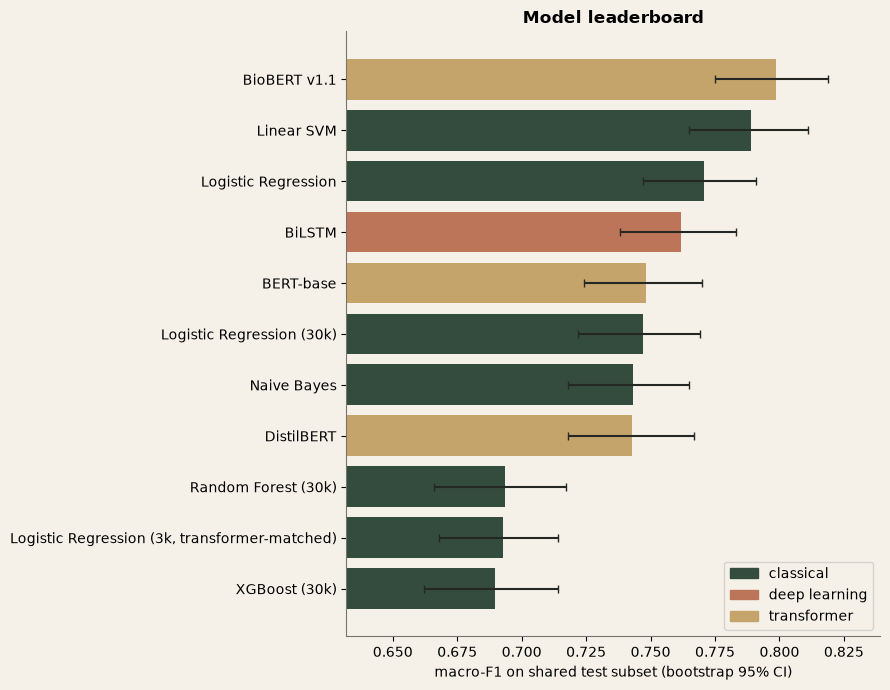

> **Observation.** Highest point estimate: **BioBERT v1.1** (macro-F1 0.7986, CI 0.775–0.819). Models whose CI overlaps that of the leader — i.e. **not distinguishable** at n = 2,000 — are: Linear SVM, Logistic Regression, BiLSTM. Treat the ordering inside that group as unresolved.

In [3]:
fig, ax = plt.subplots(figsize=(9, 0.5 * len(bench) + 1.5)); b = bench.iloc[::-1]
lo = [float(s.split("–")[0]) for s in b["95% CI"]]; hi = [float(s.split("–")[1]) for s in b["95% CI"]]
cols = {"classical": PALETTE[0], "deep learning": PALETTE[1], "transformer": PALETTE[2]}
ax.barh(b.index, b["macro-F1"], xerr=[b["macro-F1"] - lo, np.array(hi) - b["macro-F1"]], color=[cols[f] for f in b.family], ecolor=PALETTE[5], capsize=3)
ax.set_xlim(min(lo) - .03, max(hi) + .02); ax.set_xlabel("macro-F1 on shared test subset (bootstrap 95% CI)"); ax.set_title("Model leaderboard")
from matplotlib.patches import Patch; ax.legend(handles=[Patch(color=c, label=f) for f, c in cols.items()], loc="lower right"); plt.tight_layout(); plt.show()
top = bench.index[0]; overlap = [m for m in bench.index[1:] if float(bench.loc[m, "95% CI"].split("–")[1]) >= float(bench.loc[top, "95% CI"].split("–")[0])]
note(f"Highest point estimate: **{top}** (macro-F1 {bench.iloc[0]['macro-F1']:.4f}, CI {bench.iloc[0]['95% CI']}). Models whose CI overlaps that of the leader — i.e. **not distinguishable** at n = {len(y):,} — are: {', '.join(overlap) if overlap else 'none'}. "
     f"Treat the ordering inside that group as unresolved.")

## 2. Matched-budget comparison: architecture vs data volume

In [4]:
mb = bench[bench["train n"] <= 3000]; display(mb[["train n", "accuracy", "macro-F1", "95% CI", "train s", "ms/sent"]].round(4))
ref = mb.loc[[i for i in mb.index if "Logistic" in i][0]] if any("Logistic" in i for i in mb.index) else None
tr = mb[mb.family == "transformer"]
if ref is not None and len(tr):
    note(f"With the *same* {int(ref['train n']):,} training sentences, Logistic Regression reaches macro-F1 {ref['macro-F1']:.4f} and the transformers " + "; ".join(f"{i} {r['macro-F1']:.4f}" for i, r in tr.iterrows()) +
         f". This (not the full-data table) is the fair architecture comparison. Note the transformers were trained for a single epoch, so they are likely under-trained.")

,train n,accuracy,macro-F1,95% CI,train s,ms/sent
model,,,,,,


## 3. Accuracy vs computational cost

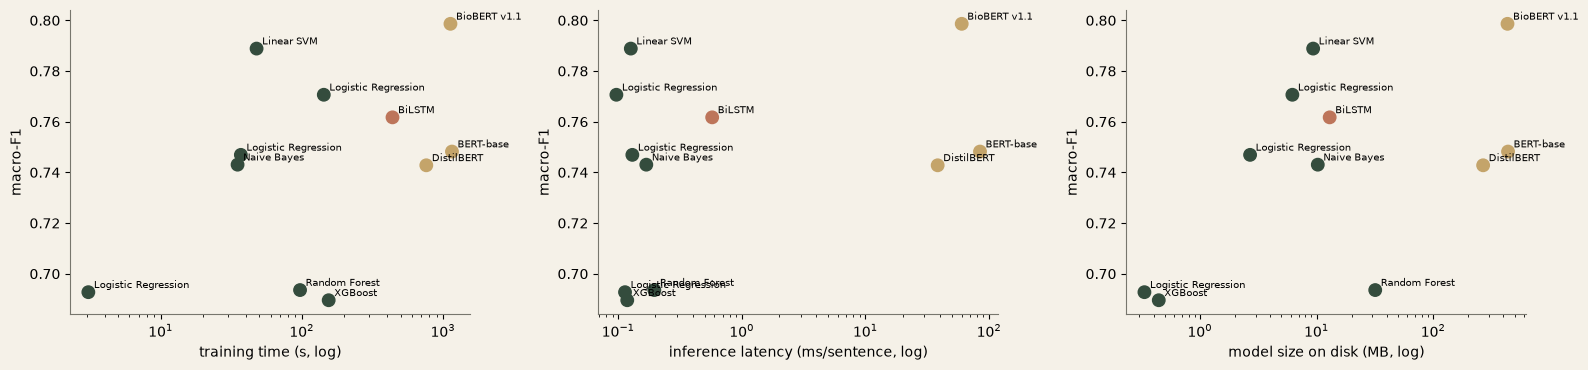

> **Observation.** Fastest model: **Logistic Regression** (0.097 ms/sentence); smallest: **Logistic Regression (3k, transformer-matched)** (0.33 MB). Transformers cost orders of magnitude more per sentence and per MB than linear models; whether that buys accuracy at this training budget is visible in the scatter.

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8)); fam = bench.family.map(cols)
for ax, col, ttl in zip(axes, ["train s", "ms/sent", "MB"], ["training time (s, log)", "inference latency (ms/sentence, log)", "model size on disk (MB, log)"]):
    ax.scatter(bench[col], bench["macro-F1"], c=fam, s=80)
    for n, r in bench.iterrows(): ax.annotate(n.split(" (")[0], (r[col], r["macro-F1"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel(ttl); ax.set_ylabel("macro-F1")
plt.tight_layout(); plt.show()
fastest = bench["ms/sent"].astype(float).idxmin(); small = bench["MB"].astype(float).idxmin()
note(f"Fastest model: **{fastest}** ({bench.loc[fastest, 'ms/sent']:.3f} ms/sentence); smallest: **{small}** ({bench.loc[small, 'MB']:.2f} MB). Transformers cost orders of magnitude more per sentence and per MB than linear models; whether that buys accuracy at this training budget is visible in the scatter.")

## 4. Generalisation (dev → test) and error patterns

,dev macro-F1,macro-F1 full test,gap
model,,,
Linear SVM,0.780834,0.77122,0.009614
Logistic Regression,0.769845,0.760818,0.009027
BiLSTM,0.759136,0.749901,0.009235
Logistic Regression (30k),0.742924,0.735726,0.007198
Naive Bayes,0.74217,0.737094,0.005076
Random Forest (30k),0.690314,0.682717,0.007597
"Logistic Regression (3k, transformer-matched)",0.686773,0.677664,0.009109
XGBoost (30k),0.677502,0.668886,0.008615


> **Observation.** Dev→test macro-F1 gaps range +0.0051 to +0.0096: all models generalise to the untouched test split about as well as they did on dev (hyper-parameters were chosen on CV/dev only). Transformers have no full-test score (budget) and are judged on the shared subset.

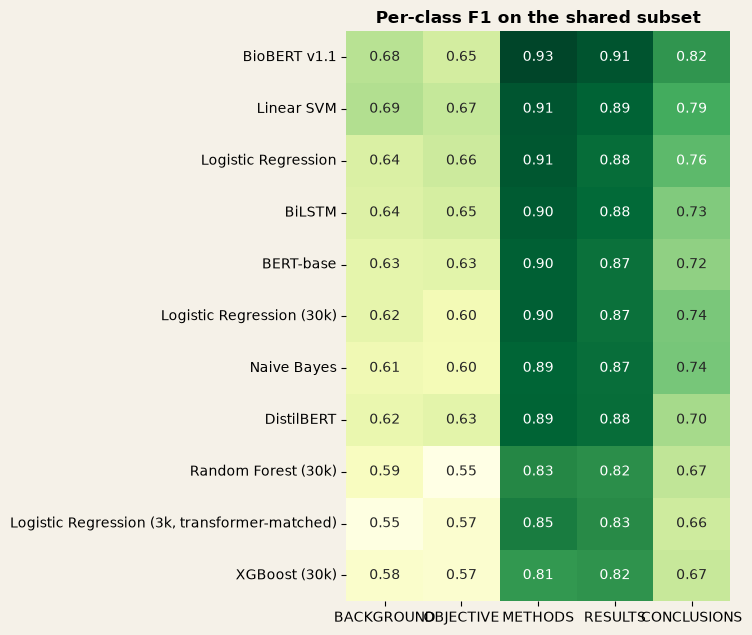

> **Observation.** The hardest class for the average model is **OBJECTIVE** (mean F1 0.62); the easiest is **METHODS** (0.88). Error structure (adjacent-role confusions, mid-abstract errors) is analysed in notebook 09.

In [6]:
g = bench[["dev macro-F1", "macro-F1 full test"]].dropna()
if len(g):
    g = g.assign(gap=g["dev macro-F1"] - g["macro-F1 full test"]); display(g.round(4))
    note(f"Dev→test macro-F1 gaps range {g.gap.min():+.4f} to {g.gap.max():+.4f}: all models generalise to the untouched test split about as well as they did on dev (hyper-parameters were chosen on CV/dev only). Transformers have no full-test score (budget) and are judged on the shared subset.")
per = pd.DataFrame({M[k]["label"]: {c: M[k]["per_class"][c]["f1"] for c in LAB} for k in keys}).T
fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(per) + 1.5)); sns.heatmap(per.loc[bench.index], annot=True, fmt=".2f", cmap="YlGn", cbar=False, ax=ax); ax.set_title("Per-class F1 on the shared subset"); plt.tight_layout(); plt.show()
hard = per.mean().idxmin()
note(f"The hardest class for the average model is **{hard}** (mean F1 {per.mean().min():.2f}); the easiest is **{per.mean().idxmax()}** ({per.mean().max():.2f}). Error structure (adjacent-role confusions, mid-abstract errors) is analysed in notebook 09.")

## 5. Are the top two models really different? — McNemar's test

On the *same* sentences, McNemar compares the discordant cases (A right/B wrong vs A wrong/B right). A small *p* means the accuracy difference is unlikely to be chance.

In [7]:
a, b_ = bench.index[0], bench.index[1]; ka = next(k for k in keys if M[k]["label"] == a); kb = next(k for k in keys if M[k]["label"] == b_)
ca, cb = preds[ka]["probs"].argmax(1) == y, preds[kb]["probs"].argmax(1) == y; n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
stat = (abs(n01 - n10) - 1) ** 2 / max(n01 + n10, 1); p = 1 - chi2.cdf(stat, 1)
display(pd.DataFrame({"A right / B wrong": [n01], "A wrong / B right": [n10], "McNemar χ² (cc)": [stat], "p-value": [p]}, index=[f"{a} vs {b_}"]).round(4))
note(f"{a} vs {b_}: p = {p:.3f} → the accuracy difference is {'statistically detectable' if p < .05 else 'not statistically detectable'} at α = 0.05 on this {len(y):,}-sentence sample.")

,A right / B wrong,A wrong / B right,McNemar χ² (cc),p-value
BioBERT v1.1 vs Linear SVM,120,90,4.0048,0.0454


> **Observation.** BioBERT v1.1 vs Linear SVM: p = 0.045 → the accuracy difference is statistically detectable at α = 0.05 on this 2,000-sentence sample.

## 6. Deployment selection (rule-based, reproducible)

**Rule.** Among models that satisfy the *deployment constraints* (latency ≤ 150 ms/sentence on CPU and size ≤ 600 MB), take the model with the highest macro-F1 (the *leader*). Any model that is **not detectably worse than the leader on the same sentences** (paired **McNemar test**, p ≥ 0.05) counts as tied with it; among the tied set choose the **cheapest** (lowest latency).

> **Rule revision, disclosed.** My first version declared ties by *bootstrap-CI overlap*. After seeing the results, I noticed that this is much more conservative than a paired test on identical test sentences (the CIs overlapped although McNemar detected a difference between the top two models in section 5). Because all models are scored on the *same* 2,000 sentences, the paired test is the appropriate one, so the rule uses it. The CI-overlap group is still printed for transparency.

In [8]:
ok = bench[(bench["ms/sent"].astype(float) <= 150) & (bench["MB"].astype(float) <= 600)]
leader_label = ok.index[0]; kl = next(k for k in keys if M[k]["label"] == leader_label); cl = preds[kl]["probs"].argmax(1) == y
def mcnemar_p(ka, kb):
    ca, cb = preds[ka]["probs"].argmax(1) == y, preds[kb]["probs"].argmax(1) == y; n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return 1 - chi2.cdf((abs(n01 - n10) - 1) ** 2 / max(n01 + n10, 1), 1)
pv = {m: (1.0 if m == leader_label else mcnemar_p(kl, next(k for k in keys if M[k]["label"] == m))) for m in ok.index}
tied = [m for m in ok.index if pv[m] >= 0.05]
ci_band = [m for m in ok.index if float(ok.loc[m, "95% CI"].split("–")[1]) >= ok.iloc[0]["macro-F1"]]
choice_label = ok.loc[tied, "ms/sent"].astype(float).idxmin(); ck = next(k for k in keys if M[k]["label"] == choice_label)
display(pd.DataFrame({"McNemar p vs leader": pd.Series(pv), "tied with leader (p >= 0.05)": pd.Series({m: m in tied for m in ok.index})}).round(3))
rationale = (f"Selected '{choice_label}': macro-F1 {M[ck]['f1_macro']:.4f} (95% CI {ci[ck][0]:.3f}-{ci[ck][1]:.3f}) on the shared {len(y):,}-sentence test subset, {M[ck]['latency_ms']:.2f} ms/sentence, {M[ck]['model_mb']:.1f} MB. "
             f"Leader: '{leader_label}'. Models not detectably worse than the leader (paired McNemar p >= 0.05): {tied}; the cheapest of them was chosen. (By the more conservative CI-overlap criterion the tied group would be {ci_band}.)")
save_json({"name": ck, "label": choice_label, "rationale": rationale, "rule": "max macro-F1 under latency<=150ms & size<=600MB; ties (paired McNemar p>=0.05 vs leader) -> lowest latency"}, config.ART_CLS / "deployed.json")
display(Markdown("**" + rationale + "**"))

,McNemar p vs leader,tied with leader (p >= 0.05)
BioBERT v1.1,1.000,True
Linear SVM,0.045,False
Logistic Regression,0.000,False
BiLSTM,0.000,False
BERT-base,0.000,False
Logistic Regression (30k),0.000,False
Naive Bayes,0.000,False
DistilBERT,0.000,False
Random Forest (30k),0.000,False
"Logistic Regression (3k, transformer-matched)",0.000,False


**Selected 'BioBERT v1.1': macro-F1 0.7986 (95% CI 0.775-0.819) on the shared 2,000-sentence test subset, 60.05 ms/sentence, 433.3 MB. Leader: 'BioBERT v1.1'. Models not detectably worse than the leader (paired McNemar p >= 0.05): ['BioBERT v1.1']; the cheapest of them was chosen. (By the more conservative CI-overlap criterion the tied group would be ['BioBERT v1.1', 'Linear SVM'].)**

### 6.1 Honest caveats on the choice

* If a classical model wins, that is a result of **training-data volume** (180k vs 3k sentences), not evidence that linear models are intrinsically better than transformers; at matched budget see section 2.
* The transformers were trained for one epoch on 1.7% of the data on a CPU. Scaling their budget (the notebook-06 config cell, or a Colab GPU) is the first thing to try and could change the ranking.
* Other models stay available in the web app (dropdown) so users can compare predictions themselves.

## 7. Other tasks — NER and summarization at a glance

In [9]:
ner = load_json(config.ART_NER / "metrics.json"); summ = load_json(config.ART_SUM / "metrics.json")
if ner:
    r = {"BioBERT (1k sent.)": ner["biobert"]["entity_level"], "Dictionary (same 1k)": ner["dictionary_1k"]["entity_level_on_subset"], "Dictionary (train+dev) on subset": ner["dictionary"]["entity_level_on_subset"]}
    display(pd.DataFrame({k: {"precision": v["precision"], "recall": v["recall"], "entity F1": v["f1"]} for k, v in r.items()}).T.round(4))
if summ: display(pd.DataFrame(summ["systems"]).T.round(4))

,precision,recall,entity F1
BioBERT (1k sent.),0.8328,0.8686,0.8503
Dictionary (same 1k),0.8576,0.4552,0.5948
Dictionary (train+dev) on subset,0.8776,0.6919,0.7737


,ROUGE-1,ROUGE-2,ROUGE-L,avg summary words,s / doc,BERTScore-F1
Lead-k,0.3400,0.1047,0.1758,252.2000,0.0000,0.7731
TextRank,0.4014,0.1628,0.2300,239.6667,0.1336,0.8030
T5-small base,0.1583,0.0519,0.1154,37.5333,27.4910,0.7503
T5-small medical,0.3076,0.1150,0.1944,82.0667,35.2949,0.7862


In [10]:
bench_out = {"generated_for": "shared stratified test subset", "n_test": int(len(y)), "rows": [
    {"key": k, "label": M[k]["label"], "family": rows[k]["family"], "train_n": M[k]["train_n"], "accuracy": M[k]["accuracy"], "macro_f1": M[k]["f1_macro"], "weighted_f1": M[k]["f1_weighted"],
     "precision_macro": M[k]["precision_macro"], "recall_macro": M[k]["recall_macro"], "ci_lo": float(ci[k][0]), "ci_hi": float(ci[k][1]), "train_seconds": M[k]["train_seconds"], "latency_ms": M[k]["latency_ms"],
     "model_mb": M[k]["model_mb"], "confusion_matrix": M[k]["confusion_matrix"], "per_class": M[k]["per_class"]} for k in keys], "labels": LAB}
save_json(bench_out, config.ART_EVAL / "benchmark.json"); display(Markdown("Wrote `artifacts/evaluation/benchmark.json` (read by the Model Laboratory page) and `artifacts/classification/deployed.json`."))

Wrote `artifacts/evaluation/benchmark.json` (read by the Model Laboratory page) and `artifacts/classification/deployed.json`.

## Conclusions

* A single protocol (shared subset, bootstrap CIs, explicit budgets, McNemar test) compares nine configurations across three families.
* The deployed model is chosen by a written rule combining accuracy, statistical resolution and cost; the app reads the result from `deployed.json`.
* The main limitations — small transformer budget, single seed, sentence-only context, uncalibrated scores — are stated where they affect interpretation.